<a href="https://colab.research.google.com/github/alyacipta/My-AI-Labs/blob/main/Computer-Vision/OpenCV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Input / Output**
1. Image
2. Video
3. Webcam

In [19]:
import os

In [14]:
image_path = '/content/bird.jpg'

img = cv2.imread(image_path)

In [9]:
if img is None:
    print(f"Error: Cannot save image because 'img' is None. Please check if '{image_path}' exists.")
else:
    os.makedirs(os.path.join('.', 'data'), exist_ok=True)
    cv2.imwrite(os.path.join('.', 'data', 'bird_out.jpg'), img)
    print("Image successfully saved to ./data/bird_out.jpg")

Error: Cannot save image because 'img' is None. Please check if './data/bird.jpg' exists.


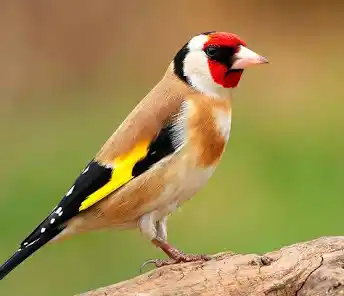

-1

In [24]:
from google.colab.patches import cv2_imshow

# Use the Colab-specific replacement function to display the image inline
cv2_imshow(img)
cv2.waitKey(0)

In [ ]:
# read video
video_path = '/content/bird.mp4'
video = cv2.VideoCapture(video_path)

In [31]:
# visualize video
ret = True
while ret:
    ret, frame = video.read()
    if ret:
        cv2_imshow(frame)
        cv2.waitKey(40)

video.release()
cv2.destroyAllWindows()

NameError: name 'video' is not defined

In [32]:
# read webcam
webcam = cv2.VideoCapture(2)


# visualize webcam
ret = True
while ret:
    ret, frame = webcam.read()
    if ret:
        cv2_imshow(frame)
        if cv2.waitKey(40) & 0xFF == ord('q'):
          break

webcam.release()
cv2.destroyAllWindows()

<IPython.core.display.Javascript object>

Saved to photo.jpg


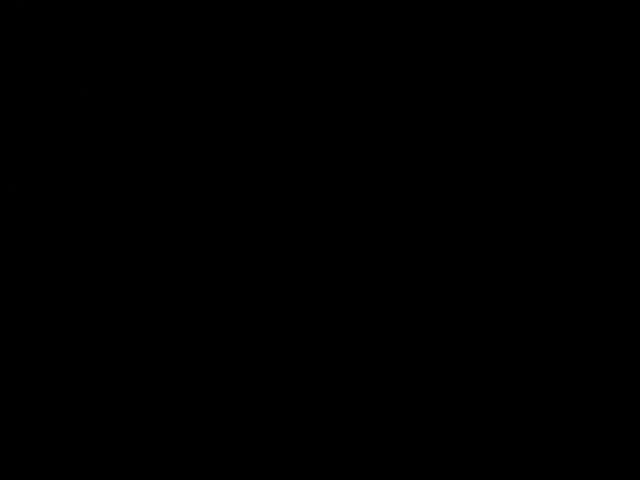

In [34]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import numpy as np
import cv2

def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

try:
  filename = take_photo()
  print('Saved to {}'.format(filename))

  # Show the image which was just taken.
  img_webcam = cv2.imread(filename)
  from google.colab.patches import cv2_imshow
  cv2_imshow(img_webcam)
except Exception as err:
  # Errors will be thrown if the user does not have a webcam or denies camera permissions
  print(str(err))

**notes:**
tampilkan webcam di g.collab perlu javascript supaya dia beneran bisa menampilkan pop up webcam nya.
Bedanya, kalau pakai di vscode langsung di local komputer, tanpa java script bisa langsung menampilkan

## **Leasson 3: Basic Operations**
1. Resizing
2. Crop

basic but important

Original Dimensions :  (296, 344, 3)
Resized Dimensions :  (640, 640, 3)


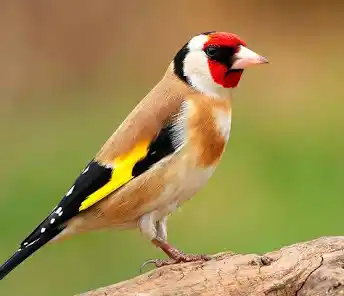

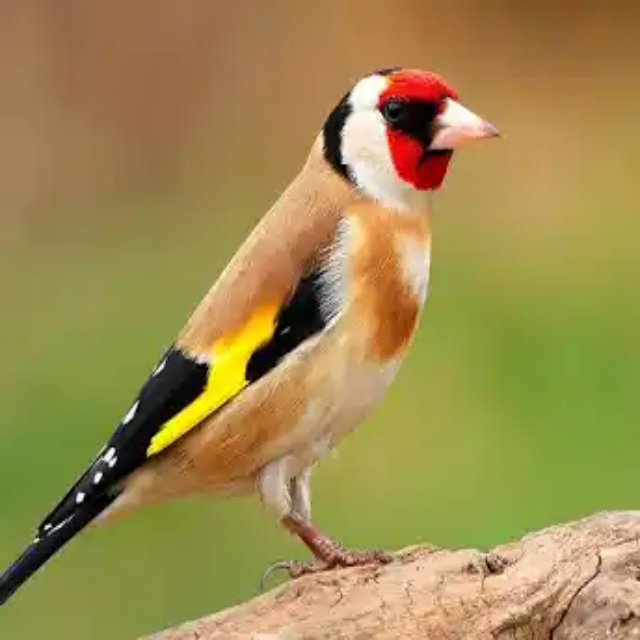

In [45]:
# resizing
from google.colab.patches import cv2_imshow

img = cv2.imread(image_path)
resized_img = cv2.resize(img, (640, 640))

print('Original Dimensions : ',img.shape)
print('Resized Dimensions : ',resized_img.shape)

# Menggunakan cv2_imshow dari patch Colab
cv2_imshow(img)
cv2_imshow(resized_img)
cv2.waitKey(0)
cv2.destroyAllWindows()

Original Dimensions :  (296, 344, 3)
Cropped Dimensions :  (96, 24, 3)


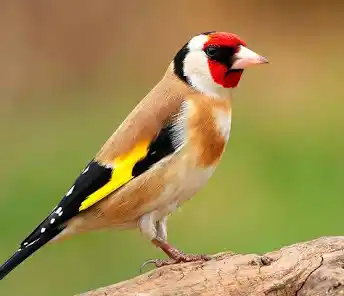

In [52]:
# crop
from google.colab.patches import cv2_imshow

img = cv2.imread(image_path)
cropped_img = img[200:740, 320:940]

print('Original Dimensions : ',img.shape)
print('Cropped Dimensions : ',cropped_img.shape)

# cv2_imshow hanya menerima variabel gambar saja
cv2_imshow(img)
cv2_imshow(cropped_img)
cv2.waitKey(0)
cv2.destroyAllWindows()

## **Lesson 4: Colorspaces**
